# Wildfire EDA — California, 1984–2023

**Milestone 3 | Exploratory analysis and documented decisions**

This notebook uses a real, daily weather + wildfire-start dataset rather than enlarging the original 244-row Algerian dataset with synthetic observations. The source contains 14,988 daily rows. The primary analysis keeps 14,610 rows from 1984-01-01 through 2023-12-31. The full 2024 calendar year and the first 12 days of 2025 are retained in the raw source file but excluded from the analysis because every row in those periods is labeled `FIRE_START_DAY=False`, unlike the rest of the record. That pattern is treated as a possible label-coverage gap, not evidence that no fires occurred.

Source: [Zenodo dataset record](https://doi.org/10.5281/zenodo.14712845), CC BY 4.0. It describes daily California weather from NOAA Climate Data Online and fire incidents from CAL FIRE. This notebook analyzes associations only; it does not establish causation or claim an operational forecast.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Find the project root whether Jupyter starts in the project or notebooks folder.
_candidates=[Path.cwd(), *Path.cwd().parents]
ROOT=next(p for p in _candidates if (p/'data/raw/CA_Weather_Fire_Dataset_1984-2025.csv').exists())
RAW=ROOT/'data/raw/CA_Weather_Fire_Dataset_1984-2025.csv'
df_all=pd.read_csv(RAW,parse_dates=['DATE']).sort_values('DATE').reset_index(drop=True)
df=df_all.loc[df_all['YEAR']<=2023].copy().reset_index(drop=True)
print(f'Raw rows: {len(df_all):,} | Analysis rows: {len(df):,} | Date range: {df.DATE.min().date()} to {df.DATE.max().date()}')
df.head()

Raw rows: 14,988 | Analysis rows: 14,610 | Date range: 1984-01-01 to 2023-12-31


,DATE,PRECIPITATION,MAX_TEMP,MIN_TEMP,AVG_WIND_SPEED,FIRE_START_DAY,YEAR,TEMP_RANGE,WIND_TEMP_RATIO,MONTH,SEASON,LAGGED_PRECIPITATION,LAGGED_AVG_WIND_SPEED,DAY_OF_YEAR
0,1984-01-01,0.0,79.0,51.0,4.70,False,1984,28.0,0.059494,1,Winter,0.0,4.700,1
1,1984-01-02,0.0,71.0,46.0,5.59,False,1984,25.0,0.078732,1,Winter,0.0,5.145,2
2,1984-01-03,0.0,70.0,47.0,5.37,False,1984,23.0,0.076714,1,Winter,0.0,5.220,3
3,1984-01-04,0.0,76.0,45.0,4.70,False,1984,31.0,0.061842,1,Winter,0.0,5.090,4
4,1984-01-05,0.0,74.0,49.0,5.14,False,1984,25.0,0.069459,1,Winter,0.0,5.100,5


## Data dictionary and source-period audit

The source includes daily weather measurements, the binary outcome `FIRE_START_DAY`, a season category, and calendar/weather-derived features. `DATE` supports ordering and time-based splitting, but will not enter the model feature matrix. The original Algerian dataset and previous notebook are retained in `legacy/` for traceability.

In [2]:
data_dictionary=pd.read_csv(ROOT/'data/processed/data_dictionary.csv')
display(data_dictionary)
audit=pd.DataFrame({
    'metric':['source rows','source date start','source date end','analysis rows','excluded rows (2024–2025)','duplicate rows in source','positive labels in analysis','analysis positive rate'],
    'value':[len(df_all),df_all.DATE.min().date(),df_all.DATE.max().date(),len(df),len(df_all)-len(df),int(df_all.duplicated().sum()),int(df.FIRE_START_DAY.sum()),round(df.FIRE_START_DAY.mean(),4)]
})
display(audit)
df.info()

,column,type,description
0,DATE,Date,Daily observation date; used only for ordering...
1,PRECIPITATION,Numeric,"Daily precipitation, inches."
2,MAX_TEMP,Numeric,"Daily maximum temperature, degrees Fahrenheit."
3,MIN_TEMP,Numeric,"Daily minimum temperature, degrees Fahrenheit."
4,AVG_WIND_SPEED,Numeric,"Daily average wind speed, mph."
5,FIRE_START_DAY,Boolean target,Whether a wildfire start was recorded on that ...
6,YEAR,Numeric,Calendar year; retained as a time-trend feature.
7,TEMP_RANGE,Numeric,"Daily maximum minus minimum temperature, degre..."
8,WIND_TEMP_RATIO,Numeric,Average wind speed divided by maximum temperat...
9,MONTH,Numeric,Calendar month.


,metric,value
0,source rows,14988
1,source date start,1984-01-01
2,source date end,2025-01-12
3,analysis rows,14610
4,excluded rows (2024–2025),378
5,duplicate rows in source,0
6,positive labels in analysis,4971
7,analysis positive rate,0.3402


<class 'pandas.DataFrame'>
RangeIndex: 14610 entries, 0 to 14609
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   DATE                   14610 non-null  datetime64[us]
 1   PRECIPITATION          14610 non-null  float64       
 2   MAX_TEMP               14610 non-null  float64       
 3   MIN_TEMP               14610 non-null  float64       
 4   AVG_WIND_SPEED         14607 non-null  float64       
 5   FIRE_START_DAY         14610 non-null  bool          
 6   YEAR                   14610 non-null  int64         
 7   TEMP_RANGE             14610 non-null  float64       
 8   WIND_TEMP_RATIO        14607 non-null  float64       
 9   MONTH                  14610 non-null  int64         
 10  SEASON                 14610 non-null  str           
 11  LAGGED_PRECIPITATION   14610 non-null  float64       
 12  LAGGED_AVG_WIND_SPEED  14610 non-null  float64       
 13  DAY_OF_YEAR 

## Data quality and missing values

There are no duplicate source rows. In the retained period, three `AVG_WIND_SPEED` values and the corresponding three `WIND_TEMP_RATIO` values are missing; the other fields used here have no missing values. We keep these rows and impute missing numeric values with medians learned from training data only in the preprocessing notebook. No rows are removed based on outlier rules: extreme weather values may be real and should be investigated before any capping.

,missing_rows
AVG_WIND_SPEED,3
WIND_TEMP_RATIO,3


Missing cells in analysis window: 6
Duplicate rows in analysis window: 0


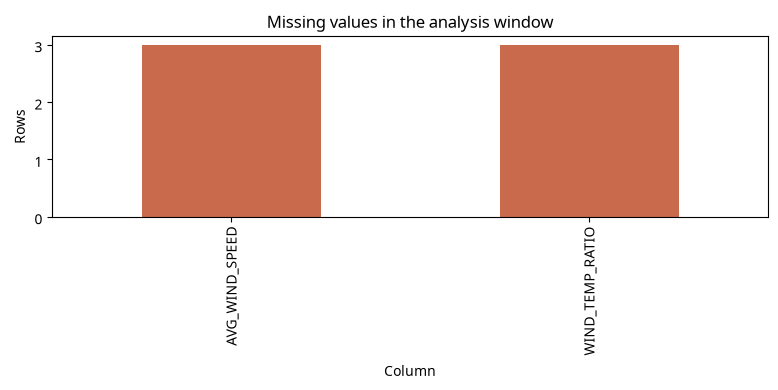

In [3]:
missing=df.isna().sum().sort_values(ascending=False)
display(missing[missing>0].rename('missing_rows').to_frame())
print('Missing cells in analysis window:',int(df.isna().sum().sum()))
print('Duplicate rows in analysis window:',int(df.duplicated().sum()))
plt.figure(figsize=(8,4))
missing[missing>0].sort_values().plot(kind='bar',color='#c96a4c')
plt.title('Missing values in the analysis window'); plt.ylabel('Rows'); plt.xlabel('Column'); plt.tight_layout()
plt.savefig(ROOT/'visuals/missing_values.png',dpi=160,bbox_inches='tight'); plt.show()

## Seasonal and year-to-year patterns

Recorded fire-start days are strongly seasonal in this dataset. Summer has the highest daily label rate, while winter has the lowest. The seasonal pattern is descriptive; it does not show that season alone causes fire starts. Year-to-year changes also matter, so a random split would mix adjacent historical periods and could overstate generalization.

,fire_start_days,days,rate,rate_percent
SEASON,,,,
Winter,272,3610,0.075346,7.5
Spring,815,3680,0.221467,22.1
Summer,2587,3680,0.702989,70.3
Fall,1297,3640,0.356319,35.6


findfont: Failed to find font weight bold for Abyssinica SIL, now using 400.


findfont: Failed to find font weight bold for Lohit Devanagari, now using 400.


findfont: Failed to find font weight bold for Lohit Tamil, now using 400.


findfont: Failed to find font weight bold for Lohit Gujarati, now using 400.


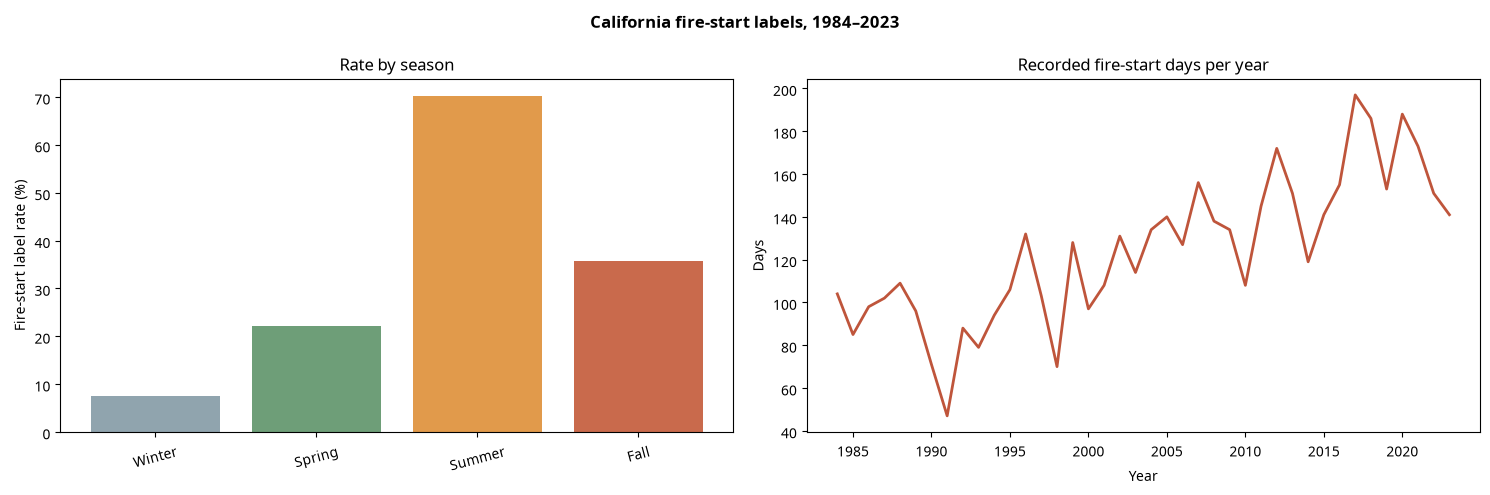

In [4]:
season_order=['Winter','Spring','Summer','Fall']
season_summary=df.groupby('SEASON').FIRE_START_DAY.agg(fire_start_days='sum',days='count',rate='mean').reindex(season_order)
display(season_summary.assign(rate_percent=(season_summary.rate*100).round(1)))
yearly=df.groupby('YEAR').FIRE_START_DAY.agg(fire_start_days='sum',rate='mean')
fig,ax=plt.subplots(1,2,figsize=(15,5))
ax[0].bar(season_summary.index,season_summary.rate*100,color=['#90a4ae','#6e9e78','#e19a4b','#c96a4c']); ax[0].set_ylabel('Fire-start label rate (%)'); ax[0].set_title('Rate by season'); ax[0].tick_params(axis='x',rotation=15)
ax[1].plot(yearly.index,yearly.fire_start_days,color='#bf553b',lw=2); ax[1].set_title('Recorded fire-start days per year'); ax[1].set_ylabel('Days'); ax[1].set_xlabel('Year')
fig.suptitle('California fire-start labels, 1984–2023',fontweight='bold'); fig.tight_layout(); fig.savefig(ROOT/'visuals/season_and_year.png',dpi=170,bbox_inches='tight'); plt.show()

## Weather relationships and feature correlations

The label rate increases across maximum-temperature quartiles in this sample. The upper temperature quartile has a much higher observed fire-start rate than the lowest quartile. This is an association, not a causal effect; seasonality and historical changes may influence both. The correlation matrix summarizes linear pairwise associations and should not be read as proof of causation or as feature importance.

,days,fire_rate,fire_rate_percent
MAX_TEMP_QUARTILE,,,
"(49.999, 65.0]",3778,0.071996,7.2
"(65.0, 70.0]",3568,0.286155,28.6
"(70.0, 75.0]",4005,0.480649,48.1
"(75.0, 106.0]",3259,0.537895,53.8


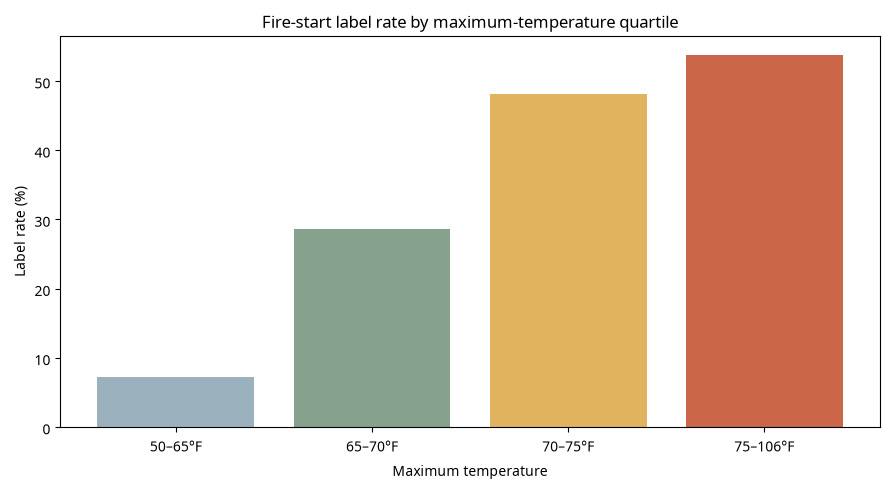

,correlation_with_target
MIN_TEMP,0.474206
MAX_TEMP,0.370978
YEAR,0.158359
MONTH,0.145630
DAY_OF_YEAR,0.143871
LAGGED_AVG_WIND_SPEED,0.076250
AVG_WIND_SPEED,0.030637
TEMP_RANGE,-0.085471
WIND_TEMP_RATIO,-0.095378
PRECIPITATION,-0.118273


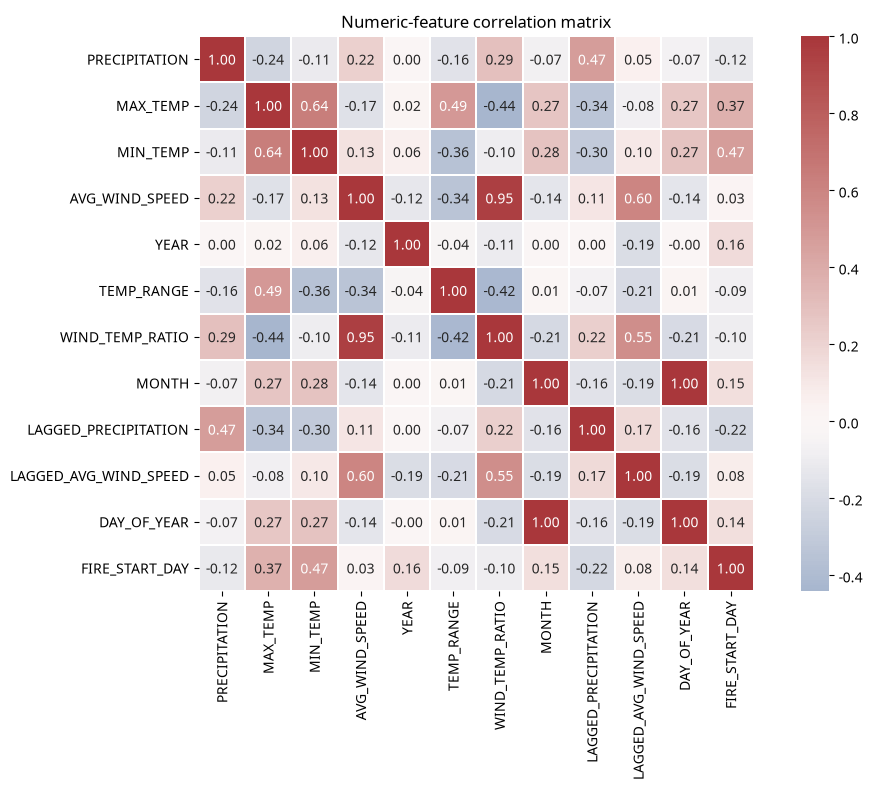

In [5]:
df_temp=df.dropna(subset=['MAX_TEMP']).copy()
df_temp['MAX_TEMP_QUARTILE']=pd.qcut(df_temp.MAX_TEMP,4,duplicates='drop')
temp_summary=df_temp.groupby('MAX_TEMP_QUARTILE',observed=True).FIRE_START_DAY.agg(days='count',fire_rate='mean')
display(temp_summary.assign(fire_rate_percent=(100*temp_summary.fire_rate).round(1)))
fig,ax=plt.subplots(figsize=(9,5))
labels=[f'{x.left:.0f}–{x.right:.0f}°F' for x in temp_summary.index]
ax.bar(labels,100*temp_summary.fire_rate,color=['#9bb2be','#86a28e','#e1b35e','#cb6648'])
ax.set_title('Fire-start label rate by maximum-temperature quartile'); ax.set_xlabel('Maximum temperature'); ax.set_ylabel('Label rate (%)'); fig.tight_layout(); fig.savefig(ROOT/'visuals/fire_rate_by_temperature.png',dpi=170,bbox_inches='tight'); plt.show()
num=df.select_dtypes(include='number').copy(); num['FIRE_START_DAY']=df.FIRE_START_DAY.astype(int)
target_corr=num.corr(numeric_only=True)['FIRE_START_DAY'].drop('FIRE_START_DAY').sort_values(ascending=False)
display(target_corr.to_frame('correlation_with_target'))
plt.figure(figsize=(11,8)); sns.heatmap(num.corr(numeric_only=True),cmap='vlag',center=0,annot=True,fmt='.2f',square=True,linewidths=.35)
plt.title('Numeric-feature correlation matrix'); plt.tight_layout(); plt.savefig(ROOT/'visuals/correlation_heatmap.png',dpi=170,bbox_inches='tight'); plt.show()

## Insights and limits

- Summer has the highest recorded fire-start day rate; winter has the lowest. This suggests that seasonal conditions should be represented in EDA and feature engineering.
- Higher maximum-temperature quartiles have higher observed target rates. This is an association and can be confounded by season and time.
- The analysis set has 14,610 daily rows and 4,971 positive labels (34.0%). Positive labels are sufficiently represented for an initial train/test preparation exercise, though rows are time-dependent and should not be randomly split.
- The source period 2024-01-01 to 2025-01-12 contains zero positive labels across 378 records. We exclude that period from primary conclusions and modeling preparation pending confirmation of label completeness.

The next notebook creates the final chronological split and fits all learned preprocessing only on the training period. No model is trained at this milestone.

In [6]:
# Persist the EDA-window copy for the project submission. Missing source values are retained here.
df.to_csv(ROOT/'data/processed/california_wildfire_1984_2023.csv',index=False)
print('Saved:',ROOT/'data/processed/california_wildfire_1984_2023.csv')

Saved: /home/ubuntu/work/wildfire/wildfire_project/data/processed/california_wildfire_1984_2023.csv
